# Receitas federais dos Estados Unidos: análise e regressão com Random Forest

| Identificação | Preencher ou confirmar antes da entrega |
|---|---|
| Instituição | PUC-SP — conforme material da disciplina; confirmar denominação |
| Disciplina | [PREENCHER — nome oficial da disciplina] |
| Professor(a) | [PREENCHER] |
| Integrante 1 | [PREENCHER — nome e identificação acadêmica] |
| Integrante 2 | [PREENCHER — nome e identificação acadêmica] |
| Turma | [PREENCHER] |
| Data de entrega | [PREENCHER — dd/mm/aaaa] |

**Dataset:** Budget — U.S. federal receipts and estimates by account.  
**Última revisão técnica:** 21/10/2026; essa data não substitui a data de entrega.

O trabalho reúne fundamentação, análise exploratória e experimento retrospectivo
de regressão com comparação temporal. A hipótese avaliada é se uma Random Forest,
usando três receitas anteriores, calendário e categorias, supera persistência.

**Execução:** abrir este arquivo na pasta notebooks ou iniciar Jupyter na raiz
do projeto; selecionar o ambiente Python e usar Restart Kernel and Run All.
O JSON é lido por caminho relativo. Não há download ou instalação nas células.
O notebook original da disciplina e o JSON bruto são preservados.


## 2. Objetivos

Investigar a estrutura das receitas e estimativas, validar tipos e integridade,
examinar códigos e séries temporais e formular uma tarefa de regressão supervisionada
com implementação de RandomForestRegressor e comparação com persistência. Produzir visualizações
interpretáveis e estabelecer uma avaliação temporal sem vazamento.

O LAB solicita Random Forest com outro conjunto do Vega Datasets, experimentação
com regressão, visualizações e discussão de Decision Tree versus Random Forest.
Budget foi autorizado pelo usuário e não aparece na lista recebida de datasets
de outras equipes. As tarefas Titanic são exemplos da disciplina e não análises do Budget.

**Evidência:** “Documentado” indica informação de fonte; “Observado” indica cálculo
deste arquivo; “Proposto” indica decisão ainda não implementada; “Pendente”
indica informação não confirmada.


## 3. Introdução à Inteligência Artificial

Inteligência Artificial estuda sistemas capazes de executar tarefas como percepção,
raciocínio, planejamento e previsão. Algumas abordagens utilizam regras explícitas;
outras aprendem padrões a partir de exemplos. Aqui, a aplicação é uma previsão
quantitativa de receitas, com limitações de dados públicos históricos. Uma
previsão estatística não explica, por si só, relações causais.


## 4. Machine Learning e aprendizagem supervisionada

Machine Learning é uma área da IA na qual algoritmos aprendem regularidades dos dados.
Na aprendizagem supervisionada, cada exemplo contém atributos explicativos X e
uma resposta conhecida y. Classificação prevê categorias; regressão prevê quantidades.

A proposta é prever uma receita futura usando informações anteriores disponíveis.
A avaliação deverá utilizar anos que não participaram do ajuste. Repetições
da mesma série criam dependência; uma divisão aleatória de linhas poderia gerar
uma avaliação excessivamente otimista.


### 4.1. Treino, teste, generalização e overfitting

Treino é a amostra usada para aprender o modelo; teste estima o desempenho em
observações fora desse ajuste. Aqui, generalizar significa prever anos posteriores
das mesmas linhas contábeis, não contas inéditas.

Overfitting ocorre quando o modelo se ajusta a particularidades do treino e perde
capacidade de previsão em dados novos. Profundidade e tamanho das folhas controlam
complexidade, mas um teste ruim não prova isoladamente sobreajuste: mudança de
regime, atributos insuficientes e dificuldade de extrapolação também são hipóteses.

Engenharia de atributos transforma o histórico em entradas úteis. As defasagens
t−1, t−2 e t−3 representam o passado da própria série. A ordem temporal deve ser
respeitada mesmo quando os cálculos são feitos em uma tabela única.


## 5. Random Forest para regressão

Uma árvore de regressão divide o espaço de atributos em regiões e associa a cada
folha uma previsão numérica. Random Forest combina muitas árvores, geralmente
com amostras bootstrap e seleção aleatória de atributos nas divisões.
RandomForestRegressor produz a média das previsões das árvores.

A média tende a reduzir a variância de uma árvore isolada, mas não elimina
sobreajuste, vazamento ou mudanças nos dados. Profundidade, tamanho mínimo das folhas
e número de árvores afetam custo e generalização. Uma floresta costuma ser mais
estável que uma árvore única, com maior custo e menor facilidade de interpretação.
árvores não extrapolam tendências como modelos lineares; isso importa para receitas crescentes.

Códigos são categorias, não magnitudes. A codificação deste experimento é ajustada
somente no treino. Importância por impureza pode favorecer alta cardinalidade; uma análise
futura deverá discutir essa limitação e considerar permutação.

Fonte: [Scikit-learn — forests](https://scikit-learn.org/stable/modules/ensemble.html#forest).
A implementação e os resultados aparecem após a análise exploratória.


### 5.1. Árvore individual versus floresta

| Aspecto | Árvore de regressão individual | Random Forest |
|---|---|---|
| Construção | Uma sequência de divisões | Muitas árvores e média das previsões |
| Interpretabilidade | Regras rastreáveis, principalmente se rasa | Análise global exige resumos e ferramentas |
| Variância | Pode mudar muito com alterações da amostra | Diversidade e média tendem a reduzir variância |
| Sobreajuste | Árvores profundas podem memorizar particularidades | Reduz instabilidade, mas ainda exige controle |
| Custo | Menor custo de treino, armazenamento e previsão | Mais árvores aumentam tempo e memória |
| Vantagem neste problema | Facilita inspecionar regras de receitas passadas | Combina padrões e interações entre séries |
| Extrapolação | Folhas não prolongam tendências fora da amostra | A média das árvores mantém essa limitação |

A comparação é conceitual. Não foi treinada uma árvore individual como terceiro
modelo e não se atribui a ela desempenho não medido.
Fontes: [árvores](https://scikit-learn.org/stable/modules/tree.html) e
[florestas](https://scikit-learn.org/stable/modules/ensemble.html#forest).


## 6. Dataset, fonte e procedência

**Documentado:** [Vega Budget](https://vega.github.io/vega-datasets/datasets/budget/)
distribui receitas e estimativas por conta, com fonte OMB. A edição local veio
do Vega Datasets **3.2.1**.

[GovInfo — Budget FY 2016, Receipts](https://www.govinfo.gov/app/details/BUDGET-2016-DB/BUDGET-2016-DB-3)
registra publicação em **02/02/2015**. FY 2016 identifica o exercício do orçamento,
não a data de publicação. A expressão “produced in 2016” da descrição Vega não
será usada para datar o documento.

As dimensões anunciadas serão verificadas localmente. A inspeção anterior
registrou divergência do SHA-1 do manifesto; os bytes do CDN e do tag oficial
v3.2.1 no GitHub eram iguais. Isso é rastreabilidade, não comprovação de precisão econômica.

[CDN da versão](https://cdn.jsdelivr.net/npm/vega-datasets@3.2.1/data/budget.json) e
[arquivo no GitHub](https://github.com/vega/vega-datasets/blob/v3.2.1/data/budget.json).


## 7. Bibliotecas utilizadas

Pandas e NumPy organizam dados; Matplotlib e Seaborn produzem gráficos.
Scikit-learn implementa a floresta, a codificação de categorias, o pipeline e
as métricas. A execução usa os pacotes já disponíveis, sem instalação.


In [1]:
from pathlib import Path
import json
import hashlib
import platform
import re
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestRegressor
from IPython.display import display, HTML
from html import escape

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 14)
pd.set_option("display.max_colwidth", 70)
display(pd.DataFrame({
    "componente": ["Python", "Pandas", "NumPy", "Matplotlib", "Seaborn", "Scikit-learn"],
    "versão": [platform.python_version(), pd.__version__, np.__version__,
               matplotlib.__version__, sns.__version__, sklearn.__version__]
}))
print("Bibliotecas disponíveis; modelagem após a análise exploratória.")


def formatar_numero(valor, casas=2):
    return f"{valor:,.{casas}f}".replace(",", "_").replace(".", ",").replace("_", ".")

def tabela_formatada(tabela, formatos, titulo):
    html = tabela.to_html(formatters=formatos, escape=True)
    html = html.replace("<thead>", "<caption>" + escape(titulo) + "</caption><thead>", 1)
    display(HTML(html))

def tabela_metricas(tabela, titulo):
    formatos = {"MAE": lambda v: formatar_numero(v, 2),
                "RMSE": lambda v: formatar_numero(v, 2),
                "R²": lambda v: formatar_numero(v, 6)}
    tabela_formatada(tabela, formatos,
                    titulo + " — MAE/RMSE em milhares de US$; R² sem unidade")

def tabela_detalhada(tabela, titulo):
    # Manter resultados completos sem ocupar toda a leitura principal.
    display(HTML("<details><summary>" + escape(titulo) + "</summary>" +
                 tabela.to_html(escape=True) + "</details>"))


,componente,versão
0,Python,3.11.9
1,Pandas,2.3.3
2,NumPy,2.3.3
3,Matplotlib,3.11.2
4,Seaborn,0.13.2
5,Scikit-learn,1.9.1


Bibliotecas disponíveis; modelagem após a análise exploratória.


## 8. Carregamento por caminho relativo

A resolução admite execução na raiz ou na pasta notebooks. Se nenhuma dessas
localizações contiver o arquivo, a execução para com mensagem clara. O JSON
bruto não é editado nem embutido no notebook.


In [2]:
candidatos = [Path("data/raw/budget.json"), Path("../data/raw/budget.json")]
arquivo = next((p for p in candidatos if p.is_file()), None)
if arquivo is None:
    raise FileNotFoundError(
        "Budget completo não encontrado. Execute na raiz do projeto ou em notebooks/ "
        "e confira data/raw/budget.json. Não será usado outro dataset."
    )
raiz = arquivo.resolve().parents[2]
hash_budget_inicial = hashlib.sha256(arquivo.read_bytes()).hexdigest()
notebook_original = raiz / "PUCSP_CS_AI_11_AI_ML_RandomForest.ipynb"
hash_original_inicial = hashlib.sha256(notebook_original.read_bytes()).hexdigest()
registros = json.loads(arquivo.read_text(encoding="utf-8"))
if not isinstance(registros, list) or not all(isinstance(r, dict) for r in registros):
    raise ValueError("O arquivo deve conter uma lista JSON de registros tabulares.")
df_bruto = pd.DataFrame(registros)
print("Caminho relativo utilizado:", arquivo)
print("Formato: lista JSON de registros; bytes:", arquivo.stat().st_size)
print("SHA-256:", hash_budget_inicial)
del registros


Caminho relativo utilizado: data\raw\budget.json
Formato: lista JSON de registros; bytes: 391353
SHA-256: 13eeecc0993fc767df37eac8e151522a5bdaee78adcd3e7e37fe10c9ca71ea96


## 9. Inspeção inicial e dimensões


In [3]:
print("shape:", df_bruto.shape)
display(df_bruto.head()[["Agency name", "Account code", "Account name", "1962", "2014", "2020"]])
df_bruto.info()
display(df_bruto.describe(include="all").T)
assert df_bruto.shape == (237, 72), "Dimensões diferentes da edição validada."


shape: (237, 72)


,Agency name,Account code,Account name,1962,2014,2020
0,Department of Health and Human Services,800415,"Supplemental Catastrophic Premium, Refunds, FSMI",0,0,0
1,Department of Health and Human Services,818210,FHICCR supplemental catastrophic premium,0,0,0
2,Department of the Treasury,551010,Private Collection Agent Program,0,0,0
3,Governmental Receipts,11050,Individual Income Taxes,"45,571,090","1,394,538,000","2,118,356,000"
4,Governmental Receipts,508110,Presidential Election Campaign Fund,0,"30,000","50,000"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 237 entries, 0 to 236
Data columns (total 72 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Source Category Code     237 non-null    int64 
 1   Source category name     237 non-null    object
 2   Source subcategory       237 non-null    int64 
 3   Source subcategory name  237 non-null    object
 4   Agency code              237 non-null    int64 
 5   Agency name              237 non-null    object
 6   Bureau code              237 non-null    int64 
 7   Bureau name              237 non-null    object
 8   Account code             237 non-null    int64 
 9   Account name             237 non-null    object
 10  Treasury Agency code     237 non-null    int64 
 11  On- or off-budget        237 non-null    object
 12  1962                     237 non-null    object
 13  1963                     237 non-null    object
 14  1964                     237 non-null    o

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Source Category Code,237.0,NaN,NaN,NaN,935.565401,1.829879,931.0,934.0,937.0,937.0,938.0
Source category name,237,8,Misc. Governmental Receipts,134,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source subcategory,237.0,NaN,NaN,NaN,2.531646,4.209056,0.0,0.0,0.0,5.0,15.0
Source subcategory name,237,12,Misc. Governmental Receipts,134,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Agency code,237.0,NaN,NaN,NaN,171.725738,287.979631,1.0,11.0,15.0,202.0,901.0
...,...,...,...,...,...,...,...,...,...,...,...
2016,237,107,0,102,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017,237,113,0,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018,237,115,0,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019,237,111,0,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interpretação — observado:** cada linha reúne descrições e valores de vários
períodos. As 237 linhas não são 237 anos. Frequências de textos não substituem
estatísticas monetárias; estas serão calculadas após conversão. Valores até 2020
não comprovam que todos os anos contenham receitas realizadas.


## 10. Dicionário preliminar das colunas

Os nomes originais são preservados. A interpretação dos campos descritivos segue
a seção 6 do [guia OMB FY 2016](https://www.govinfo.gov/content/pkg/BUDGET-2016-DB/pdf/BUDGET-2016-DB-4.pdf),
que documenta a edição utilizada neste experimento.


In [4]:
colunas_anuais = sorted(
    [c for c in df_bruto.columns if re.fullmatch(r"\d{4}", c)], key=int
)
colunas_valores = [c for c in df_bruto.columns if c in colunas_anuais or c == "TQ"]
colunas_descritivas = [c for c in df_bruto.columns if c not in colunas_valores]
definicoes = {
    "Source Category Code": "Código da categoria de receita",
    "Source category name": "Nome da categoria de receita",
    "Source subcategory": "Código da subcategoria",
    "Source subcategory name": "Nome da subcategoria",
    "Agency code": "Código do órgão",
    "Agency name": "Nome do órgão",
    "Bureau code": "Código da subdivisão do órgão",
    "Bureau name": "Nome da subdivisão",
    "Account code": "Código da conta",
    "Account name": "Nome da conta",
    "Treasury Agency code": "Código do órgão atribuído pelo Tesouro",
    "On- or off-budget": "Indicador de inclusão no orçamento"
}
dicionario = pd.DataFrame([
    {"coluna": c,
     "papel": ("valor temporal especial" if c == "TQ" else
               "valor anual" if c in colunas_anuais else "categoria ou identificação"),
     "descrição preliminar": definicoes.get(c, "Receita do período indicado no campo"),
     "tipo lido": str(df_bruto[c].dtype)}
    for c in df_bruto.columns
])
tabela_detalhada(dicionario, "Dicionário completo — 72 colunas")
print("Anos:", colunas_anuais[0], "a", colunas_anuais[-1], "—", len(colunas_anuais))
print("Descritivos:", len(colunas_descritivas), "; valores incluindo TQ:", len(colunas_valores))


,coluna,papel,descrição preliminar,tipo lido
0,Source Category Code,categoria ou identificação,Código da categoria de receita,int64
1,Source category name,categoria ou identificação,Nome da categoria de receita,object
2,Source subcategory,categoria ou identificação,Código da subcategoria,int64
3,Source subcategory name,categoria ou identificação,Nome da subcategoria,object
4,Agency code,categoria ou identificação,Código do órgão,int64
5,Agency name,categoria ou identificação,Nome do órgão,object
6,Bureau code,categoria ou identificação,Código da subdivisão do órgão,int64
7,Bureau name,categoria ou identificação,Nome da subdivisão,object
8,Account code,categoria ou identificação,Código da conta,int64
9,Account name,categoria ou identificação,Nome da conta,object


Anos: 1962 a 2020 — 59
Descritivos: 12 ; valores incluindo TQ: 60


**Interpretação:** códigos representam identidade e hierarquia. Bureau precisa do
contexto do órgão; subcategoria, da categoria. Nome de conta não garante unicidade.
O dicionário é preliminar: não resolve a continuidade econômica das séries.


## 11. Análise dos tipos de dados


In [5]:
display(df_bruto.dtypes.astype(str).value_counts().rename_axis("tipo").to_frame("colunas"))
display(df_bruto[colunas_descritivas].nunique().to_frame("valores distintos"))
print("Tipos Python nos campos temporais:",
      sorted({type(v).__name__ for v in df_bruto[colunas_valores].to_numpy().ravel()}))


,colunas
tipo,
object,66
int64,6


,valores distintos
Source Category Code,8
Source category name,8
Source subcategory,4
Source subcategory name,12
Agency code,40
Agency name,40
Bureau code,6
Bureau name,42
Account code,231
Account name,232


Tipos Python nos campos temporais: ['str']


**Interpretação — observado:** os valores temporais chegam como texto. Os códigos
chegam como inteiros, mas armazenamento não os transforma em medidas. Uma futura
codificação categórica não deverá supor que código maior significa mais receita.


## 12. Ausências, duplicados e valores não numéricos


In [6]:
def limpar_numero(serie):
    return serie.astype("string").str.strip().str.replace(",", "", regex=False)

limpos = df_bruto[colunas_valores].apply(limpar_numero)
convertidos = limpos.apply(pd.to_numeric, errors="coerce")
invalidos = convertidos.isna() & df_bruto[colunas_valores].notna()
texto_original = df_bruto[colunas_valores].astype("string")
# Conferir também o agrupamento de milhares antes de retirar as vírgulas.
formato_invalido = texto_original.apply(
    lambda s: ~s.str.strip().str.fullmatch(
        r"[+-]?(?:\d+|\d{1,3}(?:,\d{3})+)", na=False
    ) & s.notna()
)
auditoria = pd.DataFrame({
    "válidos (não nulos)": df_bruto.notna().sum(),
    "nulos": df_bruto.isna().sum(),
    "textos vazios": df_bruto.apply(
        lambda s: s.map(lambda v: isinstance(v, str) and not v.strip()).sum()),
    "distintos": df_bruto.nunique(dropna=True)
})
tabela_detalhada(auditoria, "Auditoria completa — válidos, nulos e distintos por coluna")
print("Duplicados integrais:", int(df_bruto.duplicated().sum()))
print("Falhas de conversão:", int(invalidos.sum().sum()))
print("Formatos inesperados no texto original:", int(formato_invalido.sum().sum()))
if invalidos.to_numpy().any() or formato_invalido.to_numpy().any():
    display(df_bruto[colunas_valores].where(invalidos | formato_invalido).dropna(how="all"))


,válidos (não nulos),nulos,textos vazios,distintos
Source Category Code,237,0,0,8
Source category name,237,0,0,8
Source subcategory,237,0,0,4
Source subcategory name,237,0,0,12
Agency code,237,0,0,40
Agency name,237,0,0,40
Bureau code,237,0,0,6
Bureau name,237,0,0,42
Account code,237,0,0,231
Account name,237,0,0,232


Duplicados integrais: 0
Falhas de conversão: 0
Formatos inesperados no texto original: 0


**Interpretação — observado:** não foram detectados nulos, textos vazios,
duplicados integrais ou falhas de conversão. Isso não comprova integridade
econômica: zeros podem representar situações distintas e o histórico pode ter
sido reclassificado. Repetição de código não equivale a duplicação integral.


## 13. Conversão segura das colunas anuais


In [7]:
if invalidos.to_numpy().any() or formato_invalido.to_numpy().any():
    raise ValueError("Conversão interrompida: revisar valores temporais inválidos.")
df = df_bruto.copy(deep=True)
df[colunas_valores] = convertidos.astype("int64")
assert df[colunas_valores].notna().all().all()
display(df[colunas_valores].dtypes.value_counts().to_frame("colunas"))
display(df[colunas_valores].describe().T.head(10))
print("df_bruto preserva os textos; df contém a cópia numérica.")


,colunas
int64,60


,count,mean,std,min,25%,50%,75%,max
1962,237.0,420572.172996,3.347104e+06,0.0,0.0,0.0,0.0,45571090.0
1963,237.0,449621.324895,3.521657e+06,0.0,0.0,0.0,0.0,47587746.0
1964,237.0,475162.362869,3.670459e+06,0.0,0.0,0.0,0.0,48696942.0
1965,237.0,492899.805907,3.739246e+06,0.0,0.0,0.0,0.0,48791672.0
1966,237.0,552045.012658,4.265443e+06,0.0,0.0,0.0,0.0,55446121.0
1967,237.0,627939.831224,4.797370e+06,0.0,0.0,0.0,0.0,61525756.0
1968,237.0,645455.523207,5.061241e+06,0.0,0.0,0.0,0.0,68725513.0
1969,237.0,788530.135021,6.375109e+06,0.0,0.0,0.0,0.0,87248949.0
1970,237.0,813532.704641,6.545746e+06,0.0,0.0,0.0,0.0,90411787.0
1971,237.0,789615.713080,6.228218e+06,0.0,0.0,0.0,0.0,86230010.0


df_bruto preserva os textos; df contém a cópia numérica.


**Interpretação:** as vírgulas eram separadores de milhares, não casas decimais.
A conversão não imputa dados nem elimina sinais. TQ foi convertido para inspeção,
sem ser incluído como ano completo.


**Escala:** a conversão retira vírgulas e preserva cada inteiro, sem multiplicar
ou dividir por mil. Como o arquivo já está em milhares de dólares, 1 unidade
numérica equivale a US$ 1.000. Isso vale também para MAE e RMSE; eles não são
percentuais. Os percentuais de piora comparam erros de dois modelos.


## 14. Zeros, negativos, valores distintos e distribuição


In [8]:
perfil_valores = pd.DataFrame({
    "válidos": df[colunas_valores].notna().sum(),
    "zeros": df[colunas_valores].eq(0).sum(),
    "negativos": df[colunas_valores].lt(0).sum(),
    "positivos": df[colunas_valores].gt(0).sum(),
    "distintos": df[colunas_valores].nunique(),
    "mínimo": df[colunas_valores].min(),
    "mediana": df[colunas_valores].median(),
    "máximo": df[colunas_valores].max()
})
perfil_valores["zeros (%)"] = 100 * perfil_valores["zeros"] / len(df)
tabela_detalhada(perfil_valores, "Perfil completo — valores temporais na escala original do arquivo")
valores = df[colunas_valores].to_numpy().ravel()
print("Total de células temporais:", valores.size)
print("Zeros:", int((valores == 0).sum()), "; negativos:", int((valores < 0).sum()))
display(pd.Series(valores, name="valores de anos e TQ").describe(
    percentiles=[.01, .25, .5, .75, .9, .99]).to_frame())


,válidos,zeros,negativos,positivos,distintos,mínimo,mediana,máximo,zeros (%)
1962,237,220,0,17,18,0,0.0,45571090,92.827004
1963,237,220,0,17,18,0,0.0,47587746,92.827004
1964,237,220,0,17,18,0,0.0,48696942,92.827004
1965,237,220,0,17,18,0,0.0,48791672,92.827004
1966,237,219,0,18,19,0,0.0,55446121,92.405063
1967,237,219,0,18,19,0,0.0,61525756,92.405063
1968,237,219,0,18,19,0,0.0,68725513,92.405063
1969,237,219,0,18,19,0,0.0,87248949,92.405063
1970,237,219,0,18,19,0,0.0,90411787,92.405063
1971,237,218,0,19,20,0,0.0,86230010,91.983122


Total de células temporais: 14220
Zeros: 9415 ; negativos: 308


,valores de anos e TQ
count,1.422000e+04
mean,5.743068e+06
std,6.077554e+07
min,-1.103000e+07
1%,-1.137435e+05
25%,0.000000e+00
50%,0.000000e+00
75%,9.000000e+03
90%,8.179290e+05
99%,1.093804e+08


**Interpretação — observado:** dos 14.220 valores temporais, 9.415 são zeros e
308 são negativos. Mediana e extremos mostram por que a média é insuficiente.
O resumo mistura anos e TQ apenas para auditar células; não representa
observações anuais independentes. Zeros e negativos são mantidos. Nomes de contas
podem sugerir restituições, mas não se atribui uma causa única a todos os negativos.


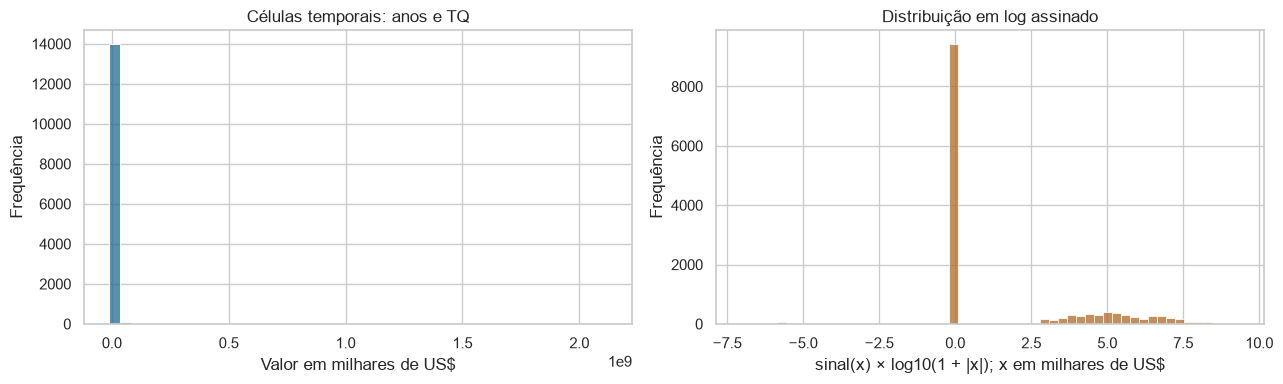

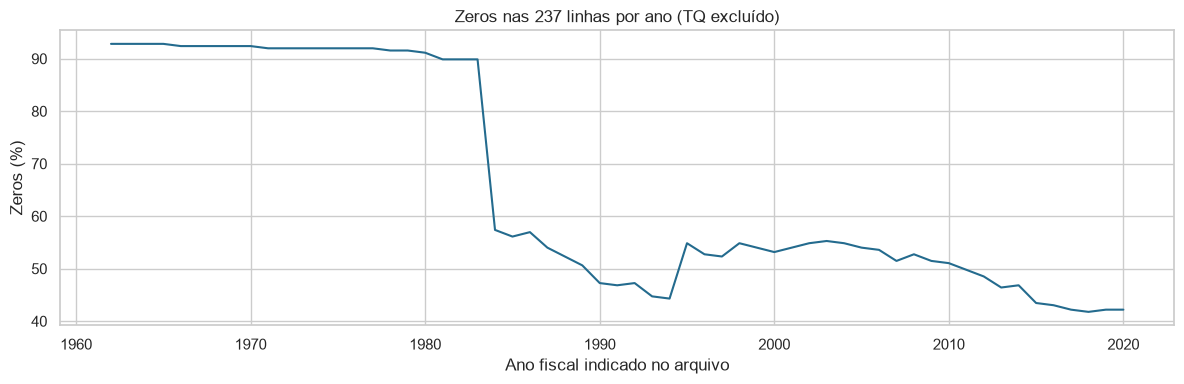

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(valores, bins=45, ax=axes[0], color="#246b8e")
axes[0].set(title="Células temporais: anos e TQ",
            xlabel="Valor em milhares de US$", ylabel="Frequência")
assinado = np.sign(valores) * np.log10(1 + np.abs(valores))
sns.histplot(assinado, bins=55, ax=axes[1], color="#b26a26")
axes[1].set(title="Distribuição em log assinado",
            xlabel="sinal(x) × log10(1 + |x|); x em milhares de US$", ylabel="Frequência")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot([int(c) for c in colunas_anuais],
        perfil_valores.loc[colunas_anuais, "zeros (%)"], color="#246b8e")
ax.set(title="Zeros nas 237 linhas por ano (TQ excluído)",
       xlabel="Ano fiscal indicado no arquivo", ylabel="Zeros (%)")
plt.tight_layout()
plt.show()


**Leitura:** a amplitude dos montantes dificulta ver valores pequenos na escala
original. O log assinado mostra negativos e zeros sem removê-los: é recurso
visual, não transformação já decidida do alvo. A proporção de zeros varia por
período; isso pode refletir cobertura, classificação ou contas sem movimento,
mas não prova ausência de informação.


In [10]:
negativos_long = (
    df.melt(id_vars=colunas_descritivas, value_vars=colunas_valores,
            var_name="período", value_name="valor")
    .query("valor < 0").sort_values("valor")
)
display(negativos_long[["Account code", "Account name", "período", "valor"]].head(10))


,Account code,Account name,período,valor
11683,15800,Transportation Fuels Tax,2010,-11030000
11446,15800,Transportation Fuels Tax,2009,-10324000
11920,15800,Transportation Fuels Tax,2011,-8644000
12157,15800,Transportation Fuels Tax,2012,-5751000
11209,15800,Transportation Fuels Tax,2008,-5127000
12631,15800,Transportation Fuels Tax,2014,-3509000
12868,15800,Transportation Fuels Tax,2015,-3398000
13999,800615,"FOASI, Refunds",2020,-3383000
10972,15800,Transportation Fuels Tax,2007,-3291000
13762,800615,"FOASI, Refunds",2019,-3244000


**Interpretação:** os dez casos mais negativos são pistas para investigação
contábil. Um rótulo como refunds não explica automaticamente cada negativo,
nem justifica substituí-lo por zero.


## 15. Campos descritivos, repetições e chaves candidatas


In [11]:
codigos = ["Source Category Code", "Source subcategory", "Agency code",
           "Bureau code", "Account code", "Treasury Agency code"]
display(pd.DataFrame({
    "distintos": df[codigos].nunique(),
    "linhas além da primeira por código": [int(df[c].duplicated().sum()) for c in codigos]
}))
display(df["Source category name"].value_counts().to_frame("linhas no arquivo"))
display(df["On- or off-budget"].value_counts().to_frame("linhas no arquivo"))
display(df.loc[df["Account code"].duplicated(keep=False),
               ["Agency code", "Bureau code", "Account code",
                "Treasury Agency code", "Account name"]].sort_values("Account code"))

chaves_candidatas = [
    ["Account code"],
    ["Treasury Agency code", "Account code"],
    ["Agency code", "Bureau code", "Account code"],
    codigos + ["On- or off-budget"]
]
display(pd.DataFrame([
    {"chave": " + ".join(k), "combinações distintas": len(df[k].drop_duplicates()),
     "repetições além da primeira": int(df.duplicated(k).sum())}
    for k in chaves_candidatas
]))
chave_serie = ["Agency code", "Bureau code", "Account code"]
assert not df.duplicated(chave_serie).any()
relacoes = [
    (["Source Category Code"], "Source category name"),
    (["Source Category Code", "Source subcategory"], "Source subcategory name"),
    (["Agency code"], "Agency name"),
    (["Agency code", "Bureau code"], "Bureau name"),
    (["Account code"], "Account name"),
    (chave_serie, "Account name")
]
display(pd.DataFrame([
    {"chave": " + ".join(k), "descrição": nome,
     "grupos com mais de uma descrição": int((df.groupby(k)[nome].nunique() > 1).sum())}
    for k, nome in relacoes
]))


# Risco de sobreposição: mesmo código em linhas distintas não autoriza somá-las.
pares_sobreposicao = []
for codigo, grupo in df.groupby("Account code"):
    if len(grupo) < 2:
        continue
    for a in range(len(grupo)):
        for b in range(a + 1, len(grupo)):
            va = grupo.iloc[a][colunas_anuais].to_numpy(dtype=float)
            vb = grupo.iloc[b][colunas_anuais].to_numpy(dtype=float)
            pares_sobreposicao.append({
                "Account code": str(codigo),
                "órgão A": grupo.iloc[a]["Agency code"],
                "órgão B": grupo.iloc[b]["Agency code"],
                "anos com ambos não zero": int(((va != 0) & (vb != 0)).sum()),
                "vetores anuais idênticos": bool(np.array_equal(va, vb))
            })
display(pd.DataFrame(pares_sobreposicao))
print("Vetores anuais repetidos além do primeiro (inclui linhas zeradas):",
      int(df[colunas_anuais].duplicated().sum()))


,distintos,linhas além da primeira por código
Source Category Code,8,229
Source subcategory,4,233
Agency code,40,197
Bureau code,6,231
Account code,231,6
Treasury Agency code,32,205


,linhas no arquivo
Source category name,
Misc. Governmental Receipts,134
Social Insurance Taxes and Contributions,43
Excise Taxes,38
Customs Duties,13
Individual Income Taxes,5
Corporation Income Taxes,2
Estate and Gift Taxes,1
Legislative Proposals,1


,linhas no arquivo
On- or off-budget,
On-budget,227
Off-budget,10


,Agency code,Bureau code,Account code,Treasury Agency code,Account name
147,15,0,10900,20,Federal tax withheld from payments to non-resident aliens
121,9,0,10900,75,Federal tax withheld from payments to non-resident aliens
233,901,0,65000,20,"Deposit of earnings, Federal Reserve System"
151,15,0,65000,20,"Deposit of Earnings, Federal Reserve System"
135,11,0,83400,15,Breached bond penalties
194,24,0,83400,70,Breached Bond Penalties
163,15,0,104000,20,"Fines, Penalties, and Forfeitures, Customs, Commerce, and Antitrus..."
137,11,0,104000,15,"Fines, Penalties, and Forfeitures, Customs, Commerce, and Antitrus..."
54,10,0,502930,14,"Excise Taxes, Federal Aid to Wildlife Restoration Fund"
59,15,0,502930,20,"Excise Taxes, Federal Aid to Wildlife Restoration Fund, Interior"


,chave,combinações distintas,repetições além da primeira
0,Account code,231,6
1,Treasury Agency code + Account code,236,1
2,Agency code + Bureau code + Account code,237,0
3,Source Category Code + Source subcategory + Agency code + Bureau c...,237,0


,chave,descrição,grupos com mais de uma descrição
0,Source Category Code,Source category name,0
1,Source Category Code + Source subcategory,Source subcategory name,0
2,Agency code,Agency name,0
3,Agency code + Bureau code,Bureau name,0
4,Account code,Account name,4
5,Agency code + Bureau code + Account code,Account name,0


,Account code,órgão A,órgão B,anos com ambos não zero,vetores anuais idênticos
0,10900,9,15,2,False
1,65000,15,901,0,False
2,83400,11,24,0,False
3,104000,11,15,1,False
4,502930,10,15,0,False
5,520910,5,15,0,False


Vetores anuais repetidos além do primeiro (inclui linhas zeradas): 0


**Interpretação — observado:** Account code tem 231 valores distintos em 237
linhas. Treasury Agency code + Account code ainda deixa uma repetição.
**Agency code + Bureau code + Account code** é única nesta edição e será a
chave candidata, sem agrupar automaticamente nomes parecidos.

Unicidade estrutural não prova continuidade econômica por décadas. Grafias e
redistribuições entre órgãos exigem revisão. Frequência de categoria conta
linhas, não participação monetária. A chave ainda requer revisão semântica.


**Conservador:** as linhas permanecem separadas. A auditoria de códigos/vetores
não certifica ausência de sobreposição ou subtotais. Portanto, não se calcula
total nacional nem se consolida contas por nome ou código. O alvo será o valor
da linha contábil na classificação desta edição.


## 16. Estrutura temporal e evolução dos valores


In [12]:
anos = [int(c) for c in colunas_anuais]
print("Anos consecutivos:", anos == list(range(min(anos), max(anos) + 1)))
print("TQ separado dos", len(anos), "anos completos.")
painel = df.melt(
    id_vars=colunas_descritivas, value_vars=colunas_anuais,
    var_name="ano", value_name="receita"
)
painel["ano"] = painel["ano"].astype(int)
print("Linhas derivadas no formato longo:", len(painel))
print("Duplicados chave + ano:", int(painel.duplicated(chave_serie + ["ano"]).sum()))
display(painel.groupby("ano")["receita"].agg(
    linhas="size", não_zeros=lambda x: x.ne(0).sum(), mínimo="min", máximo="max"
).iloc[[0, 14, 15, 20, -1]])


Anos consecutivos: True
TQ separado dos 59 anos completos.
Linhas derivadas no formato longo: 13983
Duplicados chave + ano: 0


,linhas,não_zeros,mínimo,máximo
ano,,,,
1962,237,17,0,45571090
1976,237,19,0,131602555
1977,237,19,0,157626065
1982,237,24,0,297744492
2020,237,137,-3383000,2118356000


**Interpretação:** as 13.983 linhas do painel são reorganização, não novos dados
independentes. Há 59 anos por linha, com diferenças de cobertura. O recorte da
modelagem será definido na seção 20, com base na documentação confirmada na seção 17.


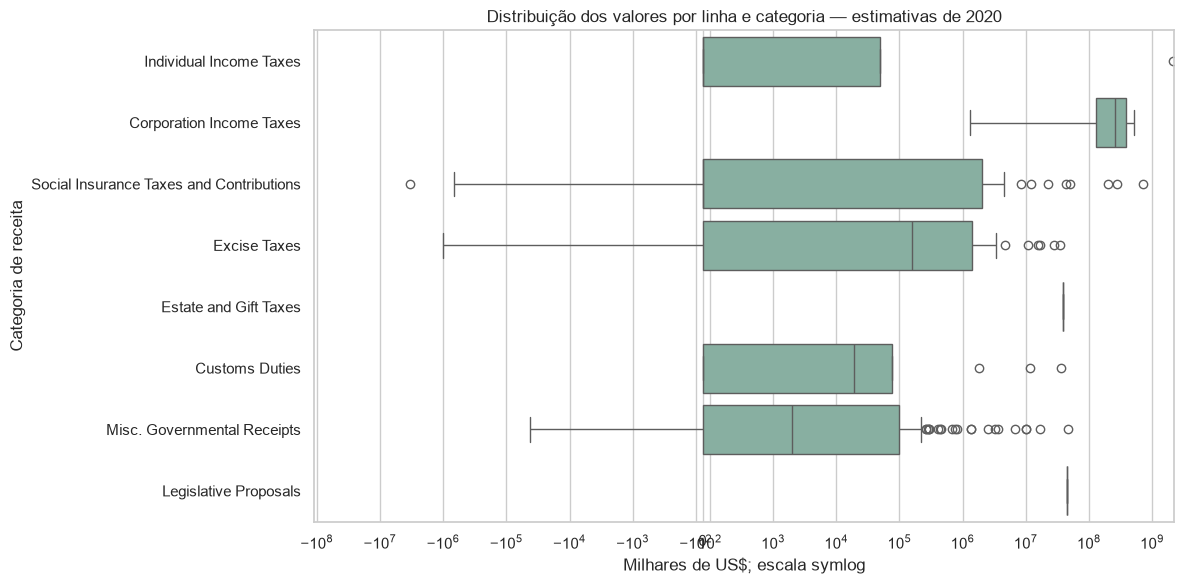

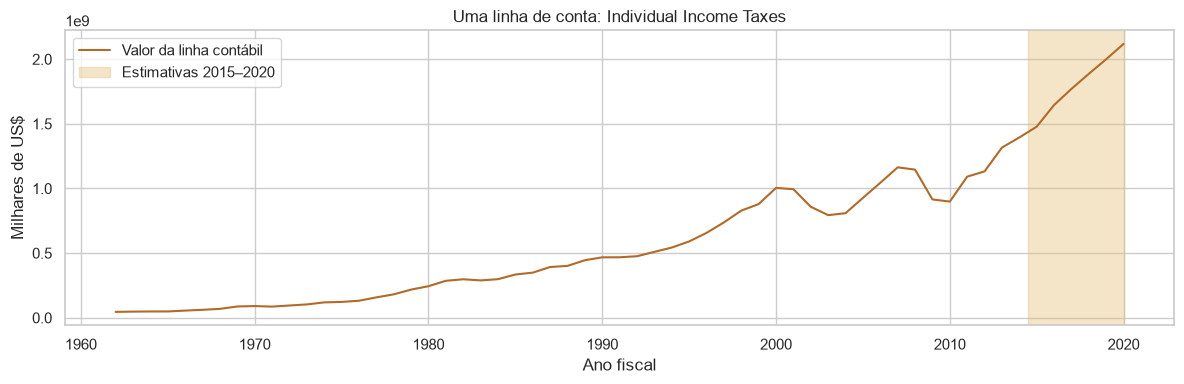

,Agency code,Bureau code,Account code,Account name
3,901,0,11050,Individual Income Taxes


In [13]:
# Comparação das linhas por categoria sem somar montantes.
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df, x=colunas_anuais[-1], y="Source category name",
            color="#82b5a3", ax=ax)
ax.set_xscale("symlog", linthresh=1000)
ax.set(title="Distribuição dos valores por linha e categoria — estimativas de 2020",
       xlabel="Milhares de US$; escala symlog", ylabel="Categoria de receita")
plt.tight_layout()
plt.show()

selecao = df.loc[df["Account name"].eq("Individual Income Taxes")]
assert len(selecao) == 1
linha_conta = selecao.iloc[0]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(anos, linha_conta[colunas_anuais].to_numpy(dtype=float), color="#b26a26",
        label="Valor da linha contábil")
ax.axvspan(2014.5, 2020, color="#e4bf7a", alpha=.4, label="Estimativas 2015–2020")
ax.set(title="Uma linha de conta: Individual Income Taxes",
       xlabel="Ano fiscal", ylabel="Milhares de US$")
ax.legend()
plt.tight_layout()
plt.show()
display(selecao[chave_serie + ["Account name"]])


**Leitura:** os boxplots comparam distribuições de valores individuais, sem somar
contas. Symlog conserva zeros e negativos. O gráfico temporal mostra uma única
linha de conta; a faixa distingue estimativas. TQ não participa dessas curvas.
Esses gráficos não são totais nacionais.

As escalas diferem muito entre linhas. A avaliação examinará também erros por ano
e categoria. O histórico inteiro foi visto na EDA: o teste é uma separação temporal,
mas não uma amostra nunca inspecionada pelo autor.


## 17. TQ, unidade e histórico — documentação confirmada

O [guia OMB FY 2016](https://www.govinfo.gov/content/pkg/BUDGET-2016-DB/pdf/BUDGET-2016-DB-4.pdf)
foi localizado nesta etapa, dentro do pacote oficial GovInfo:

- Seções 1.b–1.c, página impressa 2: TQ é julho–setembro de 1976; valores
  em milhares de dólares.
- Seção 6, página impressa 9: 1962–2014 são realizados; 2015–2020, estimativas.
- Seções 1.a e 1.d: histórico reclassificado; antes de 1982, detalhe de receitas
  não representa integralmente contas individuais.

**Decisão:** usar 1982–2014, excluir TQ e todas as estimativas da modelagem.
Sem ajuste inflacionário. **Limitação:** chave única não garante continuidade
institucional; zeros/negativos exigem contexto específico. Não há reconciliação
de totais nem certificação de ausência de sobreposição.


In [14]:
status_temporal = pd.DataFrame({
    "ano": anos,
    "status": ["realizado" if ano <= 2014 else "estimativa" for ano in anos],
    "uso na modelagem": ["elegível" if 1982 <= ano <= 2014 else "excluído" for ano in anos]
})
display(status_temporal.groupby(["status", "uso na modelagem"])["ano"].agg(["min", "max", "size"]))
print("TQ é período extraordinário: preservado no bruto, excluído das defasagens.")


min   max  size
status     uso na modelagem                  
estimativa excluído          2015  2020     6
realizado  elegível          1982  2014    33
           excluído          1962  1981    20

TQ é período extraordinário: preservado no bruto, excluído das defasagens.


**Interpretação:** a pendência documental da etapa anterior foi resolvida.
Nenhuma estimativa entra como alvo ou atributo. A classificação institucional
continua retrospectiva; o experimento não reproduz uma base disponível em cada
data histórica, nem permite inferências causais.


## 18. Unidade de observação e alvo

**Unidade:** linha contábil identificada por Agency code + Bureau code + Account code,
em um ano fiscal. As 237 identidades são distintas nesta edição. Serão acompanhadas
separadamente, sem fusão por código da conta.

**Alvo:** receita realizada dessa linha no ano t, em milhares de US$.
A finalidade é previsão de um passo à frente para essas mesmas linhas.

**Atributos:** receitas t−1, t−2, t−3; ano-alvo conhecido pelo calendário;
identidade explícita da série, categoria de receita e indicador orçamentário,
codificados como categorias. Não se fornece a receita t como atributo.

A identidade é definida pela edição retrospectiva e não comprova uma entidade
imutável. Não se exige atividade positiva para entrar na amostra; zeros e
negativos permanecem. Não há seleção com base no desempenho do teste.


In [15]:
decisoes = pd.DataFrame([
    ("Dataset", "Budget, Vega 3.2.1", "arquivo preservado"),
    ("Unidade", "linha identificada × ano fiscal", "chave estrutural única"),
    ("Alvo", "receita realizada no ano t", "milhares de US$"),
    ("Atributos numéricos", "receitas t-1, t-2, t-3 e ano t", "passado e calendário"),
    ("Identidade", "órgão + bureau + conta como categoria", "não magnitude"),
    ("TQ e estimativas", "fora da modelagem", "documentação confirmada"),
    ("Zeros/negativos", "preservar todos no recorte", "sem filtragem por resultado"),
    ("Avaliação", "últimos 5 anos históricos para teste", "um passo à frente")
], columns=["item", "decisão", "justificativa/status"])
display(decisoes)


,item,decisão,justificativa/status
0,Dataset,"Budget, Vega 3.2.1",arquivo preservado
1,Unidade,linha identificada × ano fiscal,chave estrutural única
2,Alvo,receita realizada no ano t,milhares de US$
3,Atributos numéricos,"receitas t-1, t-2, t-3 e ano t",passado e calendário
4,Identidade,órgão + bureau + conta como categoria,não magnitude
5,TQ e estimativas,fora da modelagem,documentação confirmada
6,Zeros/negativos,preservar todos no recorte,sem filtragem por resultado
7,Avaliação,últimos 5 anos históricos para teste,um passo à frente


## 19. Protocolo do experimento

Recorte 1982–2014, três defasagens e teste nos cinco últimos anos, escolhidos pela
quantidade de anos, antes de ver as métricas. Não haverá busca de hiperparâmetros.
A configuração inicial será fixa e reprodutível.

O modelo é ajustado uma vez com anos anteriores ao teste. A cada novo ano de teste,
o realizado anterior é considerado disponível para atualizar os atributos,
sem reajustar o modelo. Isso é avaliação retrospectiva de **um passo à frente**,
não uma previsão de cinco anos a partir de uma única origem.

Codificação é aprendida apenas no treino. A mesma identidade aparece em anos
diferentes, pois a tarefa é prever o futuro de linhas conhecidas. O teste não avalia
generalização para contas novas. Todas as linhas de um ano ficam no mesmo conjunto.

Não haverá soma de receitas: as métricas comparam linha/ano. Média de erros por
grupo não implica que as receitas das linhas sejam economicamente aditivas.


In [16]:
assert hashlib.sha256(arquivo.read_bytes()).hexdigest() == hash_budget_inicial
assert hashlib.sha256(notebook_original.read_bytes()).hexdigest() == hash_original_inicial
assert df_bruto.shape == (237, 72)
assert len(painel) == len(df_bruto) * len(colunas_anuais)
assert not painel.duplicated(chave_serie + ["ano"]).any()
assert "TQ" not in painel["ano"].astype(str).unique()
print("Verificações finais: JSON e notebook original intactos.")
print("Integridade da EDA confirmada; experimento implementado nas próximas seções.")


Verificações finais: JSON e notebook original intactos.
Integridade da EDA confirmada; experimento implementado nas próximas seções.


## 20. Recorte e representação das séries

Trabalharemos com cada linha da edição, sem consolidar nomes/códigos repetidos.
O início em 1982 evita o período de detalhe mais limitado. A condição não garante
homogeneidade de cada conta; define um experimento retrospectivo com limitações
de cobertura explicitadas. Nenhuma linha é eliminada por ser zero ou negativa.


In [17]:
INICIO_HISTORICO = 1982
FIM_HISTORICO = 2014
N_ANOS_TESTE = 5
DEFASAGENS = (1, 2, 3)

base_historica = painel.loc[painel["ano"].between(
    INICIO_HISTORICO, FIM_HISTORICO)].copy()
base_historica["serie_id"] = (
    base_historica[chave_serie].astype("string").agg("|".join, axis=1)
)
assert base_historica["serie_id"].nunique() == len(df)
assert not base_historica.duplicated(["serie_id", "ano"]).any()
base_historica = base_historica.sort_values(["serie_id", "ano"]).reset_index(drop=True)
assert base_historica.groupby("serie_id")["ano"].apply(
    lambda s: np.array_equal(s.to_numpy(), np.arange(1982, 2015))).all()
display(base_historica.groupby("ano")["receita"].agg(
    linhas="size", zeros=lambda s: s.eq(0).sum(), negativos=lambda s: s.lt(0).sum()
).reset_index())
print("Séries:", base_historica["serie_id"].nunique(),
      "; observações históricas:", len(base_historica))


,ano,linhas,zeros,negativos
0,1982,237,213,0
1,1983,237,213,0
2,1984,237,136,7
3,1985,237,133,10
4,1986,237,135,11
5,1987,237,128,8
6,1988,237,124,10
7,1989,237,120,10
8,1990,237,112,12
9,1991,237,111,11


Séries: 237 ; observações históricas: 7821


**Interpretação:** cada linha histórica possui uma identidade explícita e anos
consecutivos no recorte. A ausência de lacunas estruturais não permite distinguir
zero econômico de mudança na classificação. As séries não são independentes,
e linhas com nomes semelhantes não são somadas.


## 21. Construção das defasagens dentro da mesma série


In [18]:
dados_temporais = base_historica.copy()
for lag in DEFASAGENS:
    grupos = dados_temporais.groupby("serie_id", sort=False)
    dados_temporais[f"receita_lag{lag}"] = grupos["receita"].shift(lag)
    dados_temporais[f"ano_lag{lag}"] = grupos["ano"].shift(lag)

colunas_lag = [f"receita_lag{lag}" for lag in DEFASAGENS]
sem_passado = dados_temporais[colunas_lag].isna().any(axis=1)
dados_modelo = dados_temporais.loc[~sem_passado].copy()
for lag in DEFASAGENS:
    assert (dados_modelo["ano"] - dados_modelo[f"ano_lag{lag}"]).eq(lag).all()
assert dados_modelo[colunas_lag + ["receita"]].notna().all().all()
assert np.isfinite(dados_modelo[colunas_lag + ["receita"]].to_numpy()).all()
print("Linhas excluídas apenas por falta das três defasagens:", int(sem_passado.sum()))
print("Linhas elegíveis:", len(dados_modelo))
display(dados_modelo[["serie_id", "ano", "receita"] + colunas_lag].head(8))
print("Anos-alvo elegíveis:", dados_modelo["ano"].min(), "a", dados_modelo["ano"].max())


Linhas excluídas apenas por falta das três defasagens: 711
Linhas elegíveis: 7110


,serie_id,ano,receita,receita_lag1,receita_lag2,receita_lag3
3,10|0|501510,1985,223292,214897.0,0.0,0.0
4,10|0|501510,1986,216862,223292.0,214897.0,0.0
5,10|0|501510,1987,213994,216862.0,223292.0,214897.0
6,10|0|501510,1988,228261,213994.0,216862.0,223292.0
7,10|0|501510,1989,234494,228261.0,213994.0,216862.0
8,10|0|501510,1990,242304,234494.0,228261.0,213994.0
9,10|0|501510,1991,0,242304.0,234494.0,228261.0
10,10|0|501510,1992,0,0.0,242304.0,234494.0


Anos-alvo elegíveis: 1985 a 2014


**Interpretação:** shift é aplicado após ordenar por série e ano; as verificações
exigem que cada origem seja exatamente t−1, t−2 ou t−3. Somente os três primeiros
anos de cada série são retirados, por falta de passado. Não há imputação com zero,
interpolação ou média usando o futuro. A construção do painel completo com shift
causal é compatível com a avaliação de um passo especificada na seção 19.


## 22. Separação temporal e definição das entradas


In [19]:
anos_elegiveis = sorted(dados_modelo["ano"].unique())
anos_teste = anos_elegiveis[-N_ANOS_TESTE:]
corte_teste = min(anos_teste)
treino = dados_modelo.loc[dados_modelo["ano"] < corte_teste].copy()
teste = dados_modelo.loc[dados_modelo["ano"] >= corte_teste].copy()

numericas = colunas_lag + ["ano"]
categoricas = ["serie_id", "Source category name", "On- or off-budget"]
atributos = numericas + categoricas
assert "receita" not in atributos
X_train = treino[atributos].copy()
X_test = teste[atributos].copy()
for coluna in categoricas:
    X_train[coluna] = X_train[coluna].astype(str)
    X_test[coluna] = X_test[coluna].astype(str)
y_train = treino["receita"].astype(float)
y_test = teste["receita"].astype(float)

assert treino["ano"].max() < teste["ano"].min()
assert not set(treino.index).intersection(teste.index)
assert set(teste["serie_id"]).issubset(set(treino["serie_id"]))
assert X_train.notna().all().all() and X_test.notna().all().all()
resumo_divisao = pd.DataFrame([
    {"conjunto": nome, "primeiro ano": b["ano"].min(), "último ano": b["ano"].max(),
     "anos": b["ano"].nunique(), "séries": b["serie_id"].nunique(), "observações": len(b),
     "alvos zero": b["receita"].eq(0).sum(), "alvos negativos": b["receita"].lt(0).sum()}
    for nome, b in [("treino", treino), ("teste", teste)]
])
display(resumo_divisao)
display(pd.DataFrame({"atributo": atributos,
                      "papel": ["numérico"] * len(numericas) + ["categórico"] * len(categoricas)}))


,conjunto,primeiro ano,último ano,anos,séries,observações,alvos zero,alvos negativos
0,treino,1985,2009,25,237,5925,3092,222
1,teste,2010,2014,5,237,1185,575,37


,atributo,papel
0,receita_lag1,numérico
1,receita_lag2,numérico
2,receita_lag3,numérico
3,ano,numérico
4,serie_id,categórico
5,Source category name,categórico
6,On- or off-budget,categórico


**Interpretação:** o corte é o início dos cinco últimos anos elegíveis.
Todos os anos de treino precedem os de teste; cada ano permanece inteiro.
Nenhuma linha de teste entra em fit. Valores reais de um ano de teste só alimentam
as previsões de anos seguintes como passado já observado, sem retreinar.
Este resultado não representa previsão recursiva de cinco passos.


## 23. Pipeline e Random Forest inicial

OneHotEncoder representa identidade e categorias com colunas numéricas binárias,
sem impor ordem aos códigos. É ajustado no treino dentro de ColumnTransformer/Pipeline.
As variáveis numéricas passam sem padronização, que não é necessária para divisões
de árvores. Valores ausentes inesperados interrompem a execução; não há imputação
implícita. As únicas ausências criadas pelas defasagens foram tratadas na seção 21.

Configuração fixa, definida antes das métricas:
300 árvores para estabilizar a média; profundidade máxima 12 e mínimo de duas
amostras por folha para limitar complexidade; todos os atributos disponíveis
nas divisões; bootstrap ativo; random_state=42. Uma única execução, sem busca
ou ajuste orientado pelo teste. Estas escolhas são ponto de partida, não ótimo comprovado.


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

preprocessador = ColumnTransformer([
    ("numericas", "passthrough", numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas)
], remainder="drop")

hiperparametros = dict(
    n_estimators=300, max_depth=12, min_samples_split=2,
    min_samples_leaf=2, max_features=1.0, bootstrap=True,
    random_state=42, n_jobs=1, criterion="squared_error"
)
modelo_rf = Pipeline([
    ("preprocessamento", preprocessador),
    ("floresta", RandomForestRegressor(**hiperparametros))
])
display(pd.Series(hiperparametros, name="valor").to_frame())
# Única chamada de ajuste; apenas treino.
modelo_rf.fit(X_train, y_train)
encoder_ajustado = modelo_rf.named_steps["preprocessamento"].named_transformers_["categoricas"]
for coluna, categorias_aprendidas in zip(categoricas, encoder_ajustado.categories_):
    assert set(categorias_aprendidas) == set(X_train[coluna].unique())
X_train_numerico = modelo_rf.named_steps["preprocessamento"].transform(X_train)
assert np.isfinite(X_train_numerico).all()
print("Matriz de treino após codificação:", X_train_numerico.shape)
print("Modelo treinado somente com", len(y_train), "linhas de treino.")


,valor
n_estimators,300
max_depth,12
min_samples_split,2
min_samples_leaf,2
max_features,1.0
bootstrap,True
random_state,42
n_jobs,1
criterion,squared_error


Matriz de treino após codificação: (5925, 251)
Modelo treinado somente com 5925 linhas de treino.


**Interpretação:** as categorias vêm somente do treino. A identidade permite
compartilhar padrões entre séries sem tratá-las como uma única conta. O pooling
não elimina dependências contábeis; a ponderação uniforme por linha pode dar maior
impacto aos montantes extremos na função de erro quadrático.


## 24. Previsões, baseline e métricas

Baseline de persistência: a previsão para t é a receita observada em t−1.
Random Forest e baseline serão avaliados nas mesmas linhas, sem agregação de receitas.

MAE mede o erro absoluto médio; RMSE enfatiza erros grandes; ambos em milhares
de US$. R² compara a soma dos erros quadráticos com a dispersão do alvo, sem unidade:
pode ser negativo e não prova utilidade mesmo quando positivo. Muitas linhas zero
e grandes diferenças de escala podem esconder desempenhos muito distintos.
Não se usa MAPE, pois zeros e negativos prejudicam sua interpretação.


Para n observações, MAE = média de |y − previsão|; RMSE = raiz da média de
(y − previsão)²; R² = 1 − soma dos erros quadráticos / soma de (y − média(y))².
A média usada no denominador de R² é a do próprio teste; ela não é o baseline
de persistência. R² é uma descrição agregada, não um percentual de acerto.

Persistência é uma referência forte quando mudanças anuais são pequenas em
relação ao nível da série: já carrega sua escala e o último estado conhecido.
Isso justifica exigir a comparação antes de atribuir valor à floresta.


In [21]:
pred_rf = modelo_rf.predict(X_test)
pred_baseline = X_test["receita_lag1"].to_numpy(dtype=float)
assert len(pred_rf) == len(pred_baseline) == len(y_test)
assert np.isfinite(pred_rf).all() and np.isfinite(pred_baseline).all()

def avaliar(real, previsto):
    return {
        "MAE": mean_absolute_error(real, previsto),
        "RMSE": np.sqrt(mean_squared_error(real, previsto)),
        "R²": r2_score(real, previsto)
    }

metricas = pd.DataFrame({
    "Random Forest": avaliar(y_test, pred_rf),
    "Persistência": avaliar(y_test, pred_baseline)
}).T
tabela_metricas(metricas, "Tabela 1 — comparação no teste 2010–2014")

resultados = teste[["serie_id", "ano", "Account name", "Source category name", "receita"]].copy()
resultados["Random Forest"] = pred_rf
resultados["Persistência"] = pred_baseline
# Resíduo positivo = valor observado maior que previsão.
resultados["residuo_rf"] = resultados["receita"] - resultados["Random Forest"]
resultados["residuo_baseline"] = resultados["receita"] - resultados["Persistência"]

metricas_ano = pd.DataFrame([
    {"ano": ano, "modelo": nome, **avaliar(grupo["receita"], grupo[nome])}
    for ano, grupo in resultados.groupby("ano")
    for nome in ["Random Forest", "Persistência"]
])
tabela_metricas(metricas_ano, "Tabela 2 — desempenho por ano fiscal")
print("Mesma amostra de teste:", len(resultados), "observações.")
print("Alvos zero no teste:", int(y_test.eq(0).sum()),
      "; alvos negativos:", int(y_test.lt(0).sum()))
for metrica in ["MAE", "RMSE"]:
    delta = 100 * (metricas.loc["Random Forest", metrica] /
                   metricas.loc["Persistência", metrica] - 1)
    print(f"{metrica}: variação do RF em relação à persistência = {delta:+.2f}% "
          "(positivo significa erro maior)")


,MAE,RMSE,R²
Random Forest,"1.684.677,20","16.167.814,67","0,964546"
Persistência,"1.100.199,16","9.419.991,44","0,987965"


,ano,modelo,MAE,RMSE,R²
0,2010,Random Forest,"1.241.538,75","8.834.864,82","0,983625"
1,2010,Persistência,"735.877,64","4.763.137,34","0,995240"
2,2011,Random Forest,"1.613.003,79","12.903.359,28","0,973001"
3,2011,Persistência,"1.378.860,76","13.055.991,84","0,972359"
4,2012,Random Forest,"1.477.960,70","11.708.015,96","0,979498"
5,2012,Persistência,"671.004,22","4.921.905,36","0,996377"
6,2013,Random Forest,"1.759.617,99","18.502.766,00","0,961908"
7,2013,Persistência,"1.600.670,89","13.331.965,01","0,980223"
8,2014,Random Forest,"2.331.264,79","24.145.592,81","0,943113"
9,2014,Persistência,"1.114.582,28","6.969.099,65","0,995261"


Mesma amostra de teste: 1185 observações.
Alvos zero no teste: 575 ; alvos negativos: 37
MAE: variação do RF em relação à persistência = +53.12% (positivo significa erro maior)
RMSE: variação do RF em relação à persistência = +71.63% (positivo significa erro maior)


**Resultados observados:** os números acima são calculados das previsões reais desta
execução. As métricas por ano verificam estabilidade temporal, sem reajustar o modelo.
A discussão consolidada, incluindo a comparação com o baseline, aparece na seção 28.


## 25. Valores observados versus previstos e comparação visual


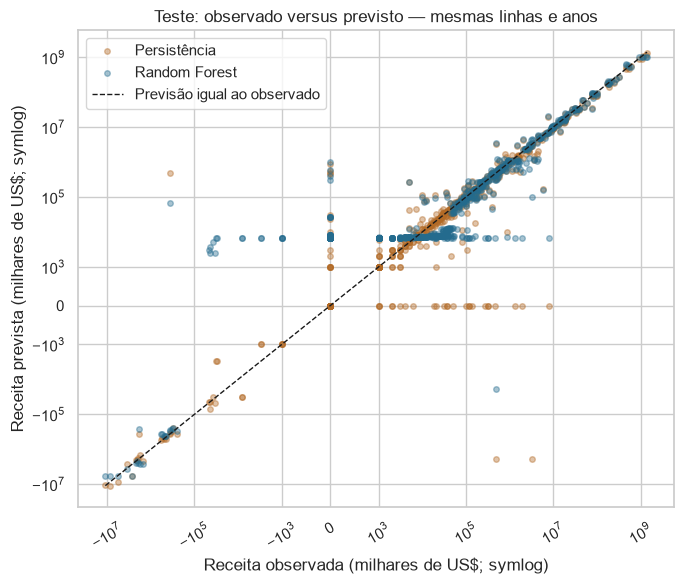

In [22]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, pred_baseline, s=16, alpha=.4, label="Persistência", color="#b26a26")
ax.scatter(y_test, pred_rf, s=16, alpha=.4, label="Random Forest", color="#246b8e")
limites = [min(y_test.min(), pred_rf.min(), pred_baseline.min()),
           max(y_test.max(), pred_rf.max(), pred_baseline.max())]
ax.plot(limites, limites, "k--", linewidth=1, label="Previsão igual ao observado")
ax.set_xscale("symlog", linthresh=1000)
ax.set_yscale("symlog", linthresh=1000)
ax.set(title="Teste: observado versus previsto — mesmas linhas e anos",
       xlabel="Receita observada (milhares de US$; symlog)",
       ylabel="Receita prevista (milhares de US$; symlog)")
ticks_monetarios = [-1e7, -1e5, -1e3, 0, 1e3, 1e5, 1e7, 1e9]
ax.set_xticks(ticks_monetarios)
ax.set_yticks(ticks_monetarios)
ax.minorticks_off()
ax.tick_params(axis="x", labelrotation=30)
ax.legend()
plt.tight_layout()
plt.show()


**Leitura:** pontos na diagonal representam previsões exatas. A escala symlog
preserva zeros e negativos e permite enxergar faixas pequenas; distâncias visuais
nessa escala não equivalem a erros monetários lineares. Sobreposição de muitos
zeros pode esconder observações. A tabela de métricas complementa o gráfico.


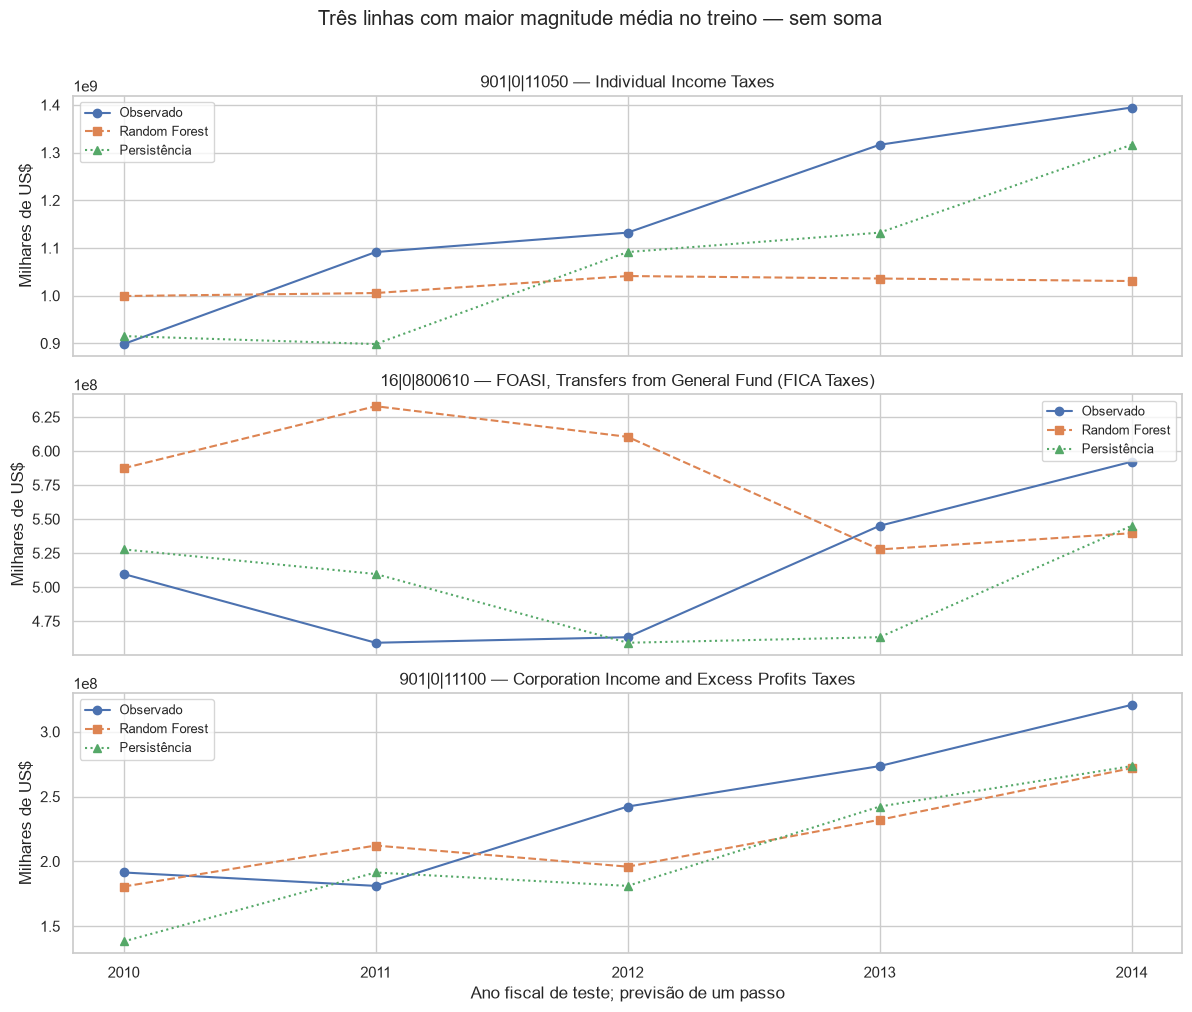

In [23]:
# Escolha de exemplos usa somente montantes de treino, não erros do teste.
series_grafico = (
    treino.assign(magnitude=treino["receita"].abs()).groupby("serie_id")["magnitude"]
    .mean().nlargest(3).index
)
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, sid in zip(axes, series_grafico):
    g = resultados.loc[resultados["serie_id"].eq(sid)].sort_values("ano")
    for nome, estilo in [("receita", "o-"), ("Random Forest", "s--"), ("Persistência", "^:")]:
        ax.plot(g["ano"], g[nome], estilo, label="Observado" if nome == "receita" else nome)
    ax.set(title=f"{sid} — {g['Account name'].iloc[0]}",
           ylabel="Milhares de US$")
    ax.legend(fontsize=9)
axes[-1].set_xlabel("Ano fiscal de teste; previsão de um passo")
axes[-1].set_xticks(anos_teste)
fig.suptitle("Três linhas com maior magnitude média no treino — sem soma", y=1.01)
plt.tight_layout()
plt.show()


**Leitura:** cada painel acompanha uma única linha contábil; a escolha dos exemplos
vem apenas do treino. Persistência repete o último realizado. A floresta pode
suavizar variações e ficar atrás de trajetórias crescentes. Os gráficos não
representam todas as séries nem um total do governo.


## 26. Resíduos e distribuição dos erros


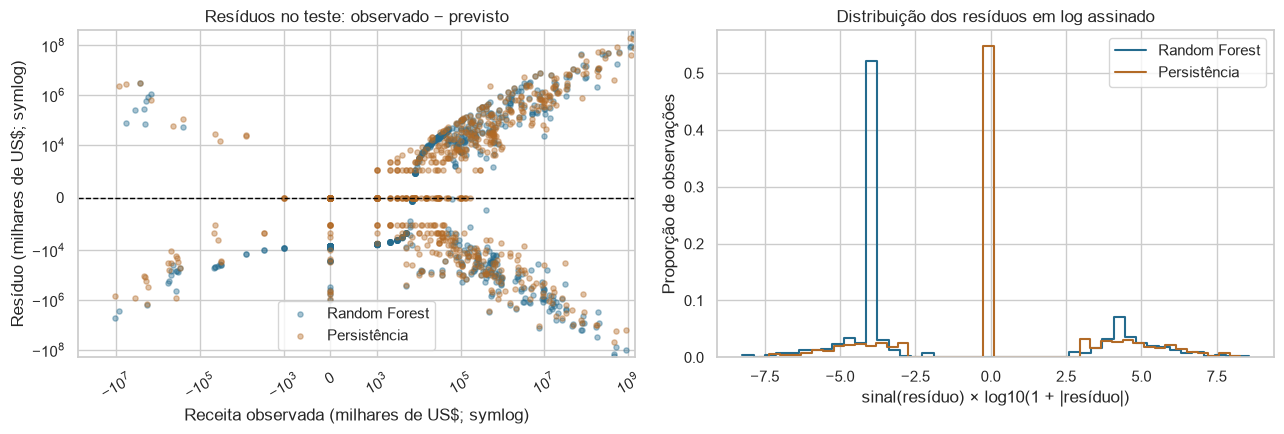

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nome, residuo, cor in [
    ("Random Forest", "residuo_rf", "#246b8e"),
    ("Persistência", "residuo_baseline", "#b26a26")
]:
    axes[0].scatter(resultados["receita"], resultados[residuo],
                    s=14, alpha=.4, label=nome, color=cor)
    v = resultados[residuo].to_numpy()
    sns.histplot(np.sign(v) * np.log10(1 + np.abs(v)), bins=45,
                 stat="probability", element="step", fill=False,
                 label=nome, color=cor, ax=axes[1])
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_xscale("symlog", linthresh=1000)
axes[0].set_yscale("symlog", linthresh=1000)
axes[0].set(title="Resíduos no teste: observado − previsto",
            xlabel="Receita observada (milhares de US$; symlog)",
            ylabel="Resíduo (milhares de US$; symlog)")
axes[1].set(title="Distribuição dos resíduos em log assinado",
            xlabel="sinal(resíduo) × log10(1 + |resíduo|)",
            ylabel="Proporção de observações")
axes[0].set_xticks([-1e7, -1e5, -1e3, 0, 1e3, 1e5, 1e7, 1e9])
axes[0].set_yticks([-1e8, -1e6, -1e4, 0, 1e4, 1e6, 1e8])
axes[0].minorticks_off()
axes[0].tick_params(axis="x", labelrotation=30)
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()


**Leitura:** resíduo positivo indica subestimação. Padrões por magnitude sugerem
que o erro muda de escala entre contas. Log assinado é apenas visualização.
Concentração no zero não demonstra bom desempenho das grandes receitas.
Não se alteram hiperparâmetros após olhar estes diagnósticos.


In [25]:
erros_categoria = resultados.assign(
    erro_abs_rf=resultados["residuo_rf"].abs(),
    erro_abs_baseline=resultados["residuo_baseline"].abs()
).groupby("Source category name").agg(
    observacoes=("receita", "size"),
    MAE_RF=("erro_abs_rf", "mean"),
    MAE_baseline=("erro_abs_baseline", "mean")
)
tabela_formatada(erros_categoria.sort_values("MAE_RF", ascending=False), {
    "MAE_RF": lambda v: formatar_numero(v, 2),
    "MAE_baseline": lambda v: formatar_numero(v, 2)
}, "Tabela 3 — MAE por categoria, em milhares de US$")
display(resultados.assign(erro_absoluto=resultados["residuo_rf"].abs()).nlargest(
    8, "erro_absoluto")[["serie_id", "ano", "Account name", "receita",
                         "Random Forest", "Persistência", "erro_absoluto"]])


,observacoes,MAE_RF,MAE_baseline
Source category name,,,
Individual Income Taxes,25,"36.887.907,99","20.512.000,00"
Corporation Income Taxes,10,"17.859.625,07","20.320.600,00"
Estate and Gift Taxes,5,"5.933.696,08","5.596.800,00"
Social Insurance Taxes and Contributions,215,"2.992.204,42","1.701.102,33"
Excise Taxes,190,"344.440,87","334.289,47"
Customs Duties,65,"249.611,42","205.615,38"
Misc. Governmental Receipts,670,"210.228,84","174.819,40"
Legislative Proposals,5,"6.854,70","0,00"


,serie_id,ano,Account name,receita,Random Forest,Persistência,erro_absoluto
6599,901|0|11050,2014,Individual Income Taxes,1394538000,1.030660e+09,1.316370e+09,3.638781e+08
6598,901|0|11050,2013,Individual Income Taxes,1316370000,1.035961e+09,1.132169e+09,2.804094e+08
2801,16|0|800610,2011,"FOASI, Transfers from General Fund (FICA Taxes)",459124000,6.329259e+08,5.096470e+08,1.738019e+08
2802,16|0|800610,2012,"FOASI, Transfers from General Fund (FICA Taxes)",463203000,6.104141e+08,4.591240e+08,1.472111e+08
6595,901|0|11050,2010,Individual Income Taxes,898508000,9.992643e+08,9.152530e+08,1.007563e+08
6597,901|0|11050,2012,Individual Income Taxes,1132169000,1.041157e+09,1.091433e+09,9.101166e+07
6596,901|0|11050,2011,Individual Income Taxes,1091433000,1.005518e+09,8.985080e+08,8.591494e+07
2800,16|0|800610,2010,"FOASI, Transfers from General Fund (FICA Taxes)",509647000,5.873776e+08,5.277080e+08,7.773060e+07


**Interpretação:** as médias acima são de erros, não somas de receitas.
A tabela identifica concentração dos erros e casos para investigação, sem
eliminar extremos ou linhas difíceis. Não há teste de significância: anos,
séries e categorias apresentam dependência e o teste cobre poucos anos.


## 27. Importância das variáveis


,importância por impureza
receita_lag1,0.817924
receita_lag2,0.093700
receita_lag3,0.084786
ano,0.003216
serie_id,0.000157
Source category name,0.000147
On- or off-budget,0.000070


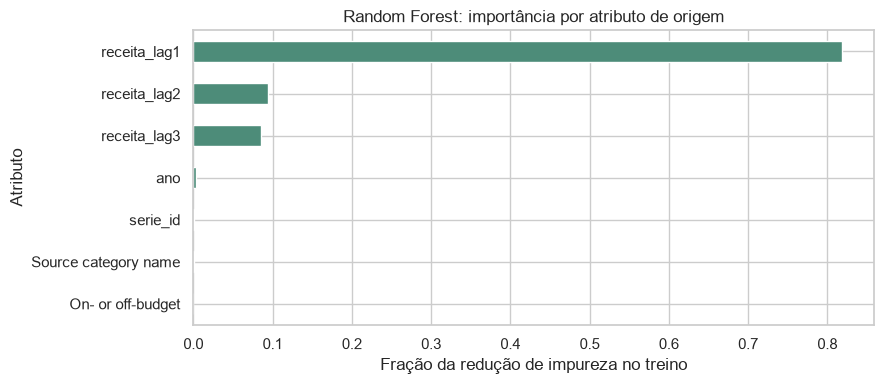

In [26]:
prep = modelo_rf.named_steps["preprocessamento"]
mdi = modelo_rf.named_steps["floresta"].feature_importances_
# Reunir as colunas one-hot pelo atributo de origem para não listar 237 identidades.
importancias = {coluna: float(mdi[i]) for i, coluna in enumerate(numericas)}
pos = len(numericas)
for coluna, categorias_aprendidas in zip(categoricas, encoder_ajustado.categories_):
    tamanho = len(categorias_aprendidas)
    importancias[coluna] = float(mdi[pos:pos + tamanho].sum())
    pos += tamanho
assert pos == len(mdi)
assert np.isclose(sum(importancias.values()), 1.0)
importancia_grupo = pd.Series(importancias, name="importância por impureza").sort_values()
display(importancia_grupo.sort_values(ascending=False).to_frame())
fig, ax = plt.subplots(figsize=(9, 4))
importancia_grupo.plot.barh(ax=ax, color="#4d8c79")
ax.set(title="Random Forest: importância por atributo de origem",
       xlabel="Fração da redução de impureza no treino", ylabel="Atributo")
plt.tight_layout()
plt.show()


**Leitura:** os valores descrevem como a floresta usou atributos no treino.
As colunas de identidade foram reunidas; isso não remove viés por cardinalidade.
Defasagens são correlacionadas e podem dividir ou substituir importância.
Importância não é causalidade nem evidência de desempenho fora da amostra.
Uma futura análise por permutação deverá respeitar a estrutura temporal.


## 28. Discussão acadêmica e conclusão do experimento

### Resultados observados

Foram previstas receitas por linha contábil e ano, com três receitas passadas,
calendário e categorias. As 237 linhas foram mantidas, inclusive zeros e negativos.
Após criar defasagens com dados de 1982 em diante, o treino contém **5.925 exemplos
de 1985–2009**, e o teste **1.185 exemplos de 2010–2014**.

| Modelo | MAE (milhares de US$) | RMSE (milhares de US$) | R² |
|---|---:|---:|---:|
| Random Forest | 1.684.677,20 | 16.167.814,67 | 0,964546 |
| Persistência | 1.100.199,16 | 9.419.991,44 | 0,987965 |

**A Random Forest não superou o baseline no resultado global:** seu MAE foi
53,12% maior e seu RMSE 71,63% maior. Persistência também
teve R² superior. A floresta teve MAE maior nos cinco anos; no RMSE, houve uma
pequena vantagem em 2011, insuficiente para mudar a conclusão agregada.
Isso não significa que ela seja pior em cada linha individual.

O teste contém **575 alvos zero e 37 negativos**, sem removê-los.
Receita t−1 recebeu aproximadamente **81,79%**
da importância por impureza, mostrando que a floresta usou principalmente a receita mais recente; isso
não equivale a aplicar a regra de persistência nem demonstra causalidade.

### Interpretação e avaliação temporal

O modelo foi ajustado uma única vez até 2009. Para prever 2011, por exemplo,
a receita de 2010 entra como informação já observada, sem novo ajuste.
Não foram usados alvos de teste no fit ou anos posteriores a cada previsão.
A avaliação é de um passo com atualização dos atributos, e não de cinco passos
a partir de 2009. Não houve busca de hiperparâmetros com o teste.

R² alto pode coexistir com erros monetários altos quando os montantes são muito dispersos;
não comprova boa previsão temporal nem ganho frente a uma regra simples.
MAE dá o erro médio por linha/ano; RMSE amplifica erros nas maiores receitas.
Não são erros de um total nacional. Muitas linhas de baixo montante podem
coexistir com erros monetários elevados nas maiores contas.

### Vantagens e limites do algoritmo

Random Forest permite relações não lineares e interações entre defasagens e
categorias, exige pouca preparação de escala e tende a reduzir a instabilidade
de uma única árvore. Em contrapartida, é mais custoso e menos simples de explicar.

A floresta aprende médias em folhas e não extrapola uma tendência crescente
como uma regressão com tendência. O ano de teste excede o maior ano do treino,
e receitas elevadas também podem exceder a faixa aprendida. Os gráficos de
contas ajudam a interpretar essa dificuldade; não isolam sua causa nem provam
que outro modelo será melhor.

### Limitações dos dados e do desenho

- A chave identifica linhas na edição FY 2016; não certifica continuidade
  econômica ou disponibilidade dessa identidade em cada ano passado.
- Sobreposição, subtotais e reclassificações não foram reconciliados.
  Nenhuma receita foi somada para formar o alvo ou as métricas.
- Muitos zeros, negativos e valores extremos tornam a distribuição desigual.
  Sinais e magnitudes foram preservados; suas causas exigem revisão contábil.
- Há somente **30 anos-alvo elegíveis**, 25 de treino e 5 de teste. As 7.110
  linhas derivadas não são amostras independentes: há dependência entre anos
  e entre contas. Não foram calculados intervalos de confiança.
- O histórico revisado e a EDA do arquivo inteiro impedem apresentar o teste
  como reconstrução prospectiva estrita ou conjunto nunca inspecionado.
- A fronteira foi documentada antes do ajuste: 2015–2020 são estimativas e
  ficaram fora de alvo e entradas. Confundi-las com realizado mudaria a tarefa.
- O resultado é de uma configuração inicial. Não há demonstração de ótimo
  nem generalização para novas contas, outros países ou versões do orçamento.

### Melhorias futuras

Antes de otimizar, revisar a identidade/cobertura das séries e preencher
integrantes. Uma próxima análise poderá usar validação temporal interna só
nos anos de treino, comparadores adicionais e erros por faixa de montante.
Se o teste atual orientar novas escolhas, ele deverá ser tratado como exploratório,
com nova avaliação independente quando houver dados adequados.

O experimento executou corretamente sob o protocolo retrospectivo descrito,
mas **não demonstrou ganho preditivo da Random Forest sobre persistência**.
Esse resultado negativo é parte da conclusão acadêmica, não motivo para ocultar
métricas ou procurar uma configuração favorável no mesmo teste.


### 28.1. O que está demonstrado e o que é hipótese

**Observado:** nesta configuração e nesta amostra, persistência teve menor MAE e
RMSE global. Nos gráficos das maiores linhas, a floresta apresenta desvios
sistemáticos em certos períodos. Não houve alteração de hiperparâmetros para
melhorar o teste.

**Explicações possíveis:** um nível persistente favorece o último valor observado;
a média de folhas pode limitar extrapolação; mudanças contábeis e regimes de receita
podem afetar relações aprendidas. Esses mecanismos são plausíveis, mas o desenho
não os isolou. Seriam necessários testes adicionais nos anos de treino para
atribuir a diferença a uma causa particular. Não se demonstrou que o pior
resultado decorra exclusivamente de overfitting.

O resultado não estabelece inferioridade universal de Random Forest em regressão.
Mostra que a configuração adotada não acrescentou ganho nesta tarefa. Um baseline
superior não invalida o experimento: torna a comparação e sua conclusão necessárias.

### 28.2. Conclusão acadêmica

O objetivo foi aplicar Random Forest a uma regressão temporal com dados reais do
Budget/Vega, de origem OMB. O problema foi prever receitas por linha contábil e ano,
mantendo zeros e negativos. A preparação converteu textos monetários sem mudar
a escala, reorganizou o histórico elegível e criou três defasagens por identidade.

A separação cronológica reservou 1985–2009 para treino e 2010–2014 para teste,
em previsões de um passo. A floresta obteve MAE de 1.684.677,20 e RMSE de
16.167.814,67 milhares de US$, enquanto persistência obteve 1.100.199,16 e
9.419.991,44. Os erros da floresta foram 53,12% e 71,63% maiores, respectivamente.

Assim, o trabalho demonstra uma implementação reprodutível e uma comparação
desfavorável à configuração de Random Forest avaliada. O R² alto não muda essa
conclusão. Revisões históricas, heterogeneidade de escalas, dependência das linhas
e apenas cinco anos de teste limitam a generalização. São melhorias possíveis
a revisão contábil das séries e validação temporal interna no treino, sem escolher
configurações repetidamente pelo teste atual.


## 29. Controle de qualidade

As verificações abaixo examinam integridade dos arquivos, separação temporal,
causalidade das defasagens e consistência entre teste e previsões.
Não substituem a revisão econômica da base nem garantem ausência de todos os vieses.


In [27]:
assert hashlib.sha256(arquivo.read_bytes()).hexdigest() == hash_budget_inicial
assert hashlib.sha256(notebook_original.read_bytes()).hexdigest() == hash_original_inicial
assert treino["ano"].max() < teste["ano"].min()
assert dados_modelo["ano"].between(1985, 2014).all()
assert len(dados_modelo) == len(treino) + len(teste)
assert not dados_modelo.duplicated(["serie_id", "ano"]).any()
assert len(y_test) == len(pred_rf) == len(pred_baseline)
assert X_train.columns.equals(X_test.columns)
assert len(modelo_rf.named_steps["floresta"].estimators_) == hiperparametros["n_estimators"]
for lag in DEFASAGENS:
    assert dados_modelo[f"ano_lag{lag}"].lt(dados_modelo["ano"]).all()
    assert dados_modelo[f"ano_lag{lag}"].le(2013).all()
print("Integridade preservada; separação temporal e defasagens verificadas.")
print("Baseline e floresta avaliados na mesma amostra; nenhum ajuste no teste.")
print("Experimento executado; qualidade preditiva depende dos resultados, não desta mensagem.")


# Chave/ano obtida independentemente das colunas de shift.
lookup = painel.set_index(chave_serie + ["ano"])["receita"]
for lag in DEFASAGENS:
    chaves_origem = dados_modelo[chave_serie + ["ano"]].copy()
    chaves_origem["ano"] -= lag
    esperado = lookup.reindex(pd.MultiIndex.from_frame(chaves_origem)).to_numpy()
    np.testing.assert_array_equal(dados_modelo[f"receita_lag{lag}"], esperado)
np.testing.assert_array_equal(y_test.to_numpy(), teste["receita"].to_numpy())
np.testing.assert_array_equal(pred_baseline, teste["receita_lag1"].to_numpy())
assert resultados.index.equals(teste.index)
assert resultados["ano"].to_numpy().tolist() == teste["ano"].to_numpy().tolist()

# Verificar que a conversão do JSON não alterou a escala.
for coluna in colunas_valores:
    esperado = df_bruto[coluna].map(lambda v: int(str(v).replace(",", "").strip()))
    np.testing.assert_array_equal(df[coluna].to_numpy(), esperado.to_numpy())

for nome, previsto in [("Random Forest", pred_rf), ("Persistência", pred_baseline)]:
    real = y_test.to_numpy(dtype=float)
    residuo = real - previsto
    sse = np.sum(residuo ** 2)
    sst = np.sum((real - real.mean()) ** 2)
    assert sst > 0
    manuais = [np.mean(np.abs(residuo)), np.sqrt(np.mean(residuo ** 2)), 1 - sse / sst]
    np.testing.assert_allclose(metricas.loc[nome, ["MAE", "RMSE", "R²"]].to_numpy(),
                               manuais, rtol=1e-12, atol=1e-12)
print("Auditoria independente: lags, alvo, baseline, escala e fórmulas das métricas OK.")


Integridade preservada; separação temporal e defasagens verificadas.
Baseline e floresta avaliados na mesma amostra; nenhum ajuste no teste.
Experimento executado; qualidade preditiva depende dos resultados, não desta mensagem.
Auditoria independente: lags, alvo, baseline, escala e fórmulas das métricas OK.


### 29.1. Registro da revisão final

- Mantidos recorte, atributos, hiperparâmetros, horizonte e baseline do experimento.
- Conferidos os valores defasados por consulta independente à chave/ano de origem,
  a escala inteira do JSON e as métricas por fórmulas NumPy.
- Corrigida a interpretação de importância: usar t−1 na floresta não equivale à
  regra de persistência; possíveis causas de desempenho foram separadas de evidências.
- Acrescentados conceitos de generalização/overfitting, comparação árvore/floresta,
  identificação editável, conclusão e formatação monetária consistente.
- Tabelas extensas continuam disponíveis em blocos expansíveis. Não se ocultam erros.
- README atualizado para a versão com treinamento e resultados.
- Limitações contábeis e de validade prospectiva permanecem declaradas.

A publicação depende de preencher a identificação e revisar a apresentação.
Não foi publicado repositório nem enviada mensagem no MS Teams nesta revisão.


Na primeira execução da revisão, o uso de Pandas Styler falhou por ausência de
Jinja2. Foi substituído por DataFrame.to_html, sem instalação e sem alteração
do modelo. A execução integral final verifica a correção; a falha transitória
foi de apresentação, não de cálculo das previsões.


## 30. Referências bibliográficas

Consultadas em 21/10/2026.

- PUC-SP. **PUCSP_CS_AI_11_AI_ML_RandomForest.ipynb**. Material da disciplina,
  original na raiz do projeto. LAB e exemplos didáticos.
- Vega. [Budget](https://vega.github.io/vega-datasets/datasets/budget/).
  Descrição, estrutura e procedência. Dados locais: release 3.2.1.
- OMB / GovInfo. [Budget FY 2016 — Receipts](https://www.govinfo.gov/app/details/BUDGET-2016-DB/BUDGET-2016-DB-3).
  Publicação: 02/02/2015.
- OMB. [Public Budget Database User's Guide, FY 2016](https://www.govinfo.gov/content/pkg/BUDGET-2016-DB/pdf/BUDGET-2016-DB-4.pdf).
  Fevereiro de 2015. Seções 1 e 6: documentação da edição analisada.
- Scikit-learn. [Documentação oficial](https://scikit-learn.org/stable/).
- Scikit-learn. [Forests](https://scikit-learn.org/stable/modules/ensemble.html#forest).
- Scikit-learn. [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).
- Scikit-learn. [Validação temporal](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split).
- Scikit-learn. [Vazamento de dados](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

- Scikit-learn. [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).
- Scikit-learn. [Métricas de regressão](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics).


- Scikit-learn. [Decision Trees](https://scikit-learn.org/stable/modules/tree.html).

A fonte dos dados é OMB, distribuída pelo Vega. Scikit-learn documenta o algoritmo,
o pré-processamento e a avaliação; não é fonte dos registros. As estatísticas e
gráficos são calculados localmente. Títulos e datas documentais foram mantidos
apenas quando identificados nas fontes.
